# Cross-Dataset Nested Kriging

This notebook implements and evaluates the **cross-dataset nested kriging layer**: a second-level Rullière aggregation that pools block centroids from all 55 per-dataset NK models into a single global pool.

## Architecture

Each per-dataset `NestedKrigingForecaster` (or `MultivariateNestedKrigingForecaster`) saves M_d block centroids after fitting.  Because datasets have different context lengths L_d, all centroids are mapped to a common d-dimensional **ACF feature space** before the cross-dataset kernel matrix is assembled:

$$\hat{y}(x^*) = c(\phi^*)^\top [C + D]^{-1} \hat{\mu}$$

where $\phi^* = \phi(x^*)$ is the ACF embedding of the query, $C_{ij} = k_{\mathrm{RBF}}(\phi_i, \phi_j)$, $D_{ii} = \hat{\sigma}^2_i$, and $\hat{\mu}_i = \hat{y}_i(\bar{x}_i)$.

## Workflow

1. **Load saved states** — scan `experiments/models/*.npz`
2. **Fit `CrossDatasetNestedKrigingForecaster`** on all loaded states
3. **Evaluate** on GIFT-Eval test windows for selected datasets
4. **Compare** cross-dataset predictions vs per-dataset NK predictions
5. **Visualise** the cross-dataset weight heatmap

In [1]:
import sys
import pathlib
import warnings
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

# Add project root to path
ROOT = pathlib.Path("..")
sys.path.insert(0, str(ROOT))

from src.nested_kriging import (
    load_nk_state,
    acf_embedding,
    CrossDatasetNestedKrigingForecaster,
)

MODELS_DIR = pathlib.Path("models")

print(f"Models directory: {MODELS_DIR.resolve()}")
saved = sorted(MODELS_DIR.glob("*.npz"))
print(f"Found {len(saved)} saved model state(s):")
for p in saved:
    print(f"  {p.name}")
# ── Auto-save figures to experiments/figures/ ───────────────────────────────
import matplotlib.pyplot as _nk_plt
if not getattr(_nk_plt.show, '_nk_patched', False):
    _nk_fig_dir = ROOT / "experiments" / "figures"
    _nk_fig_dir.mkdir(parents=True, exist_ok=True)
    _nk_fig_ctr = [0]
    _nk_max_figs = 6   # save at most 6 figures per notebook run
    _nk_show_orig = _nk_plt.show
    _NK_DS_LABEL = "cross_dataset"

    def _nk_show(*_a, **_kw):
        if _nk_fig_ctr[0] < _nk_max_figs:
            _p = _nk_fig_dir / f"{_NK_DS_LABEL}_fig{_nk_fig_ctr[0]:02d}.png"
            _nk_plt.savefig(str(_p), bbox_inches="tight", dpi=150)
            print(f"[fig saved → {_p}]")
        _nk_fig_ctr[0] += 1
        _nk_show_orig(*_a, **_kw)

    _nk_show._nk_patched = True
    _nk_plt.show = _nk_show


Models directory: /Users/jonghyeonlee/KMD_TS/experiments/models
Found 55 saved model state(s):
  LOOP_SEATTLE__5T.npz
  LOOP_SEATTLE__D.npz
  LOOP_SEATTLE__H.npz
  M_DENSE__D.npz
  M_DENSE__H.npz
  SZ_TAXI__15T.npz
  SZ_TAXI__H.npz
  bitbrains_fast_storage__5T.npz
  bitbrains_fast_storage__H.npz
  bitbrains_rnd__5T.npz
  bitbrains_rnd__H.npz
  bizitobs_application.npz
  bizitobs_l2c__5T.npz
  bizitobs_l2c__H.npz
  bizitobs_service.npz
  car_parts_with_missing.npz
  covid_deaths.npz
  electricity__15T.npz
  electricity__D.npz
  electricity__H.npz
  electricity__W.npz
  ett1__15T.npz
  ett1__D.npz
  ett1__H.npz
  ett1__W.npz
  ett2__15T.npz
  ett2__D.npz
  ett2__H.npz
  ett2__W.npz
  hierarchical_sales__D.npz
  hierarchical_sales__W.npz
  hospital.npz
  jena_weather__10T.npz
  jena_weather__D.npz
  jena_weather__H.npz
  kdd_cup_2018_with_missing__D.npz
  kdd_cup_2018_with_missing__H.npz
  m4_daily.npz
  m4_hourly.npz
  m4_monthly.npz
  m4_quarterly.npz
  m4_weekly.npz
  m4_yearly.npz
  r

In [2]:
# ── Load all saved model states ──────────────────────────────────────────────
states = []
for p in saved:
    try:
        s = load_nk_state(p)
        states.append(s)
        mv_tag = f" (MV, {s['n_channels']} ch)" if 'n_channels' in s else ""
        print(f"  {s['dataset_name']:40s}  "
              f"M={len(s['centroids']):4d}  L={s['context_length']:4d}  H={s['horizon_length']:3d}"
              f"{mv_tag}")
    except Exception as exc:
        print(f"  ERROR loading {p.name}: {exc}")

print(f"\nTotal blocks in global pool: {sum(len(s['centroids']) for s in states)}")

  LOOP_SEATTLE/5T                           M=  30  L= 288  H= 48
  LOOP_SEATTLE/D                            M=  14  L=  60  H= 30
  LOOP_SEATTLE/H                            M=  30  L= 168  H= 48
  M_DENSE/D                                 M=   5  L= 180  H= 30
  M_DENSE/H                                 M=   6  L= 168  H= 48
  SZ_TAXI/15T                               M=  30  L=  96  H= 48
  SZ_TAXI/H                                 M=  15  L= 168  H= 48
  bitbrains_fast_storage/5T                 M=  60  L=  96  H= 48 (MV, 2 ch)
  bitbrains_fast_storage/H                  M=  60  L=  96  H= 48 (MV, 2 ch)
  bitbrains_rnd/5T                          M=  60  L=  96  H= 48 (MV, 2 ch)
  bitbrains_rnd/H                           M=  60  L=  96  H= 48 (MV, 2 ch)
  bizitobs_application                      M=   8  L= 120  H= 60 (MV, 2 ch)
  bizitobs_l2c/5T                           M=  49  L=  96  H= 48 (MV, 7 ch)
  bizitobs_l2c/H                            M=  14  L= 168  H= 48 (MV, 7 ch)

In [3]:
# ── Fit CrossDatasetNestedKrigingForecaster ──────────────────────────────────
ACF_DIM = 20       # ACF embedding dimension (lags 1..20)
SIGMA_N = 1e-3     # noise floor

cdnk = CrossDatasetNestedKrigingForecaster(
    acf_dim=ACF_DIM,
    sigma_n=SIGMA_N,
).fit(states)

print(f"Fitted CrossDatasetNestedKrigingForecaster")
print(f"  M_total      = {cdnk._phi_centroids.shape[0]}")
print(f"  ACF dim      = {ACF_DIM}")
print(f"  length_scale = {cdnk.length_scale_:.4f}  (median heuristic)")
print(f"  max_H        = {cdnk._max_H}")

Fitted CrossDatasetNestedKrigingForecaster
  M_total      = 1557
  ACF dim      = 20
  length_scale = 1.8911  (median heuristic)
  max_H        = 60


[fig saved → ../experiments/figures/cross_dataset_fig00.png]


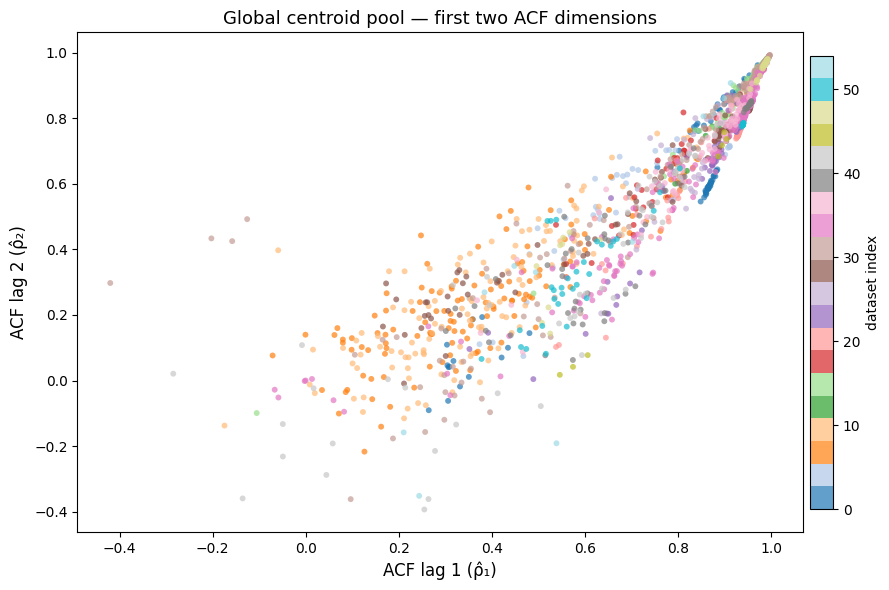

In [4]:
# ── ACF embedding visualisation ──────────────────────────────────────────────
# Show the global centroid distribution in the first 2 ACF dimensions,
# colour-coded by dataset.

# Assign a colour to each dataset
dataset_ids = []
offset = 0
for s in states:
    M = len(s['centroids'])
    dataset_ids.extend([s['dataset_name']] * M)
    offset += M

unique_ds = list(dict.fromkeys(dataset_ids))   # preserves order
ds_to_idx = {d: i for i, d in enumerate(unique_ds)}
colors = np.array([ds_to_idx[d] for d in dataset_ids], dtype=float)

phi = cdnk._phi_centroids   # (M_total, d)

fig, ax = plt.subplots(figsize=(9, 6))
sc = ax.scatter(phi[:, 0], phi[:, 1], c=colors, cmap="tab20",
                s=18, alpha=0.7, linewidths=0)
ax.set_xlabel("ACF lag 1 (ρ̂₁)", fontsize=12)
ax.set_ylabel("ACF lag 2 (ρ̂₂)", fontsize=12)
ax.set_title("Global centroid pool — first two ACF dimensions", fontsize=13)
cbar = fig.colorbar(sc, ax=ax, fraction=0.03, pad=0.01)
cbar.set_label("dataset index", fontsize=10)
plt.tight_layout()
plt.show()

[fig saved → ../experiments/figures/cross_dataset_fig01.png]




In [5]:
# ── Cross-dataset weight heatmap ─────────────────────────────────────────────
# For each state, pick its first centroid as a representative query and compute
# the Rullière weights. The heatmap shows weight[query_dataset, source_block].

n_query_datasets = min(len(states), 20)       # show at most 20
M_total = cdnk._phi_centroids.shape[0]

W = np.zeros((n_query_datasets, M_total))
query_labels = []

for qi, s in enumerate(states[:n_query_datasets]):
    q_ctx = s['centroids'][0]                  # first centroid of this dataset
    phi_q = acf_embedding(q_ctx, ACF_DIM)      # (d,)
    from src.nested_kriging import _rbf_kernel, _safe_cholesky, _EPS
    c = _rbf_kernel(phi_q[None], cdnk._phi_centroids,
                    length_scale=cdnk.length_scale_,
                    amplitude=cdnk.amplitude).ravel()
    w = np.linalg.solve(cdnk._chol_CD.T, np.linalg.solve(cdnk._chol_CD, c))
    W[qi] = w
    query_labels.append(s['dataset_name'].split("/")[0][:18])   # short label

# Column labels: one per block, labelled by dataset
block_ds_labels = []
for s in states:
    short = s['dataset_name'].split("/")[0][:12]
    for _ in range(len(s['centroids'])):
        block_ds_labels.append(short)

fig, ax = plt.subplots(figsize=(max(12, M_total * 0.22), max(5, n_query_datasets * 0.35)))
im = ax.imshow(W, aspect='auto', cmap='RdBu_r',
               vmin=-np.abs(W).max(), vmax=np.abs(W).max())
ax.set_yticks(range(n_query_datasets))
ax.set_yticklabels(query_labels, fontsize=8)
ax.set_xlabel("Global block index (coloured by source dataset)", fontsize=10)
ax.set_ylabel("Query dataset", fontsize=10)
ax.set_title("Cross-dataset Rullière weights", fontsize=13)
plt.colorbar(im, ax=ax, fraction=0.02, pad=0.01)
plt.tight_layout()
plt.show()

In [6]:
# ── Evaluation on GIFT-Eval test windows ─────────────────────────────────────
#
# Auto-discovers all datasets from saved .npz states.
# For each, evaluates the cross-dataset NK on real test windows and
# computes relative L2, MAE, and RMSE.
# The model is fast at inference — no re-fitting per series, just a kernel
# weighted average over the global centroid pool.

try:
    from gift_eval.data import Dataset
    HAS_GIFT = True
except ImportError:
    HAS_GIFT = False
    print("gift_eval not installed — skipping GIFT-Eval evaluation.")

def _rel_l2(true, pred):
    """Relative L2 error; falls back to absolute L2 when target is all-zero."""
    t = np.asarray(true, float).ravel()
    p = np.asarray(pred, float).ravel()
    d = float(np.nansum(t ** 2))
    if d < 1e-12:
        return float(np.nansum((t - p) ** 2))
    return float(np.nansum((t - p) ** 2) / d)

CONTEXT_MULT    = 3      # context_length = prediction_length × CONTEXT_MULT
MAX_EVAL_SERIES = 100    # max series per dataset (None = all)

results     = {}   # ds_name → summary metrics
all_errors  = {}   # ds_name → {rel_l2: [...], mae: [...], rmse: [...]}
eval_states = []   # states for which evaluation succeeded

if HAS_GIFT and states:
    print(f"Evaluating {len(states)} dataset(s) found in {MODELS_DIR} ...\n")

    for s in states:
        ds_name = s["dataset_name"]
        H       = int(s["horizon_length"])
        L       = H * CONTEXT_MULT

        try:
            ds = Dataset(name=ds_name, term="short")
        except Exception as exc:
            print(f"  {ds_name}: cannot load GIFT-Eval dataset ({exc}) — skipping")
            continue

        rl2s, maes, rmses = [], [], []
        n_eval = 0

        for s_idx, (ctx_entry, lbl_entry) in enumerate(ds.test_data):
            if MAX_EVAL_SERIES is not None and s_idx >= MAX_EVAL_SERIES:
                break

            ctx_raw = np.asarray(ctx_entry["target"], dtype=float).ravel()
            tgt_raw = np.asarray(lbl_entry["target"], dtype=float).ravel()
            if len(ctx_raw) < L or len(tgt_raw) < H:
                continue

            ctx_raw = ctx_raw[-L:]
            tgt_raw = tgt_raw[:H]

            # Robust normalisation (NaN-safe)
            loc   = float(np.nanmedian(ctx_raw))
            devs  = np.abs(ctx_raw - loc)
            scale = float(np.nanquantile(devs, 0.75)) if np.any(np.isfinite(devs)) else 1.0
            scale = max(scale, 1e-8)
            ctx_norm = (ctx_raw - loc) / scale

            pred_norm = cdnk.predict(ctx_norm, target_horizon=H)
            pred      = pred_norm * scale + loc

            rl2s.append(_rel_l2(tgt_raw, pred))
            maes.append(float(np.nanmean(np.abs(pred - tgt_raw))))
            rmses.append(float(np.sqrt(np.nanmean((pred - tgt_raw) ** 2))))
            n_eval += 1

        if n_eval == 0:
            print(f"  {ds_name}: no evaluable test windows — skipping")
            continue

        mean_rl2  = float(np.nanmean(rl2s))
        med_rl2   = float(np.nanmedian(rl2s))
        mean_mae  = float(np.mean(maes))
        mean_rmse = float(np.mean(rmses))

        results[ds_name] = {
            "mean_relL2":  mean_rl2,
            "median_relL2": med_rl2,
            "mean_MAE":    mean_mae,
            "mean_RMSE":   mean_rmse,
            "n_windows":   n_eval,
        }
        all_errors[ds_name] = {"rel_l2": rl2s, "mae": maes, "rmse": rmses}
        eval_states.append(s)

        print(f"  {ds_name:35s}  n={n_eval:4d}  "
              f"relL2={mean_rl2:.4f} (med {med_rl2:.4f})  "
              f"MAE={mean_mae:.4f}  RMSE={mean_rmse:.4f}")

    if results:
        print(f"\n{'Dataset':35s}  {'relL2':>8}  {'MAE':>8}  {'RMSE':>8}")
        print("-" * 70)
        for ds, m in results.items():
            print(f"  {ds:33s}  {m['mean_relL2']:8.4f}  {m['mean_MAE']:8.4f}  {m['mean_RMSE']:8.4f}")
    elif HAS_GIFT:
        print("No datasets evaluated — run the individual NK notebooks first to create .npz states in experiments/models/")
else:
    print("No saved states found in", MODELS_DIR, "— run individual NK notebooks first.")


/Users/jonghyeonlee/KMD_TS/ts/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/Users/jonghyeonlee/KMD_TS/ts/lib/python3.12/site-packages/gluonts/json.py:102: UserWarning: Using `json`-module for json-handling. Consider installing one of `orjson`, `ujson` to speed up serialization and deserialization.
  warnings.warn(
/Users/jonghyeonlee/KMD_TS/experiments/../gift_eval/data.py:151: FutureWarning: 'T' is deprecated and will be removed in a future version, please use 'min' instead.
  freq = norm_freq_str(to_offset(self.freq).name)
/Users/jonghyeonlee/KMD_TS/ts/lib/python3.12/site-packages/gluonts/dataset/common.py:263: FutureWarning: 'T' is deprecated and will be removed in a future version, please use 'min' instead.
  return pd.Period(val, freq)


Evaluating 55 dataset(s) found in models ...

  LOOP_SEATTLE/5T                      n= 100  relL2=23.8468 (med 3.3283)  MAE=154.1901  RMSE=187.5667
  LOOP_SEATTLE/D                       n= 100  relL2=9.9843 (med 3.6099)  MAE=123.7689  RMSE=138.2417


/Users/jonghyeonlee/KMD_TS/experiments/../gift_eval/data.py:151: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  freq = norm_freq_str(to_offset(self.freq).name)
/Users/jonghyeonlee/KMD_TS/ts/lib/python3.12/site-packages/gluonts/dataset/common.py:263: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  return pd.Period(val, freq)


  LOOP_SEATTLE/H                       n= 100  relL2=0.6179 (med 0.2855)  MAE=28.9068  RMSE=35.7350
  M_DENSE/D                            n=  90  relL2=65.8358 (med 25.4365)  MAE=3146.8257  RMSE=3407.3663
  M_DENSE/H                            n= 100  relL2=56.7272 (med 27.4295)  MAE=5831.6083  RMSE=6842.0076
  SZ_TAXI/15T                          n= 100  relL2=16.4889 (med 2.9393)  MAE=26.6625  RMSE=31.7420
  SZ_TAXI/H                            n= 100  relL2=3.1717 (med 1.6915)  MAE=15.2248  RMSE=18.4179
  bitbrains_fast_storage/5T            n= 100  relL2=3.2033 (med 0.9744)  MAE=1243.9267  RMSE=1640.1618
  bitbrains_fast_storage/H             n= 100  relL2=14640478.3728 (med 0.9824)  MAE=1100.7096  RMSE=1479.0872
  bitbrains_rnd/5T                     n= 100  relL2=12.0791 (med 0.9837)  MAE=435.2759  RMSE=509.1549
  bitbrains_rnd/H                      n= 100  relL2=2.6093 (med 0.9741)  MAE=529.9955  RMSE=819.7923


/Users/jonghyeonlee/KMD_TS/experiments/../gift_eval/data.py:151: FutureWarning: 'S' is deprecated and will be removed in a future version, please use 's' instead.
  freq = norm_freq_str(to_offset(self.freq).name)
/Users/jonghyeonlee/KMD_TS/ts/lib/python3.12/site-packages/gluonts/dataset/common.py:263: FutureWarning: 'S' is deprecated and will be removed in a future version, please use 's' instead.
  return pd.Period(val, freq)


  bizitobs_application                 n=  15  relL2=1358389.8667 (med 964223.0854)  MAE=46081.7763  RMSE=51232.4400
  bizitobs_l2c/5T                      n=  20  relL2=6.9371 (med 2.9406)  MAE=40.3360  RMSE=47.5170
  bizitobs_l2c/H                       n=   6  relL2=237.6170 (med 85.5680)  MAE=110.5883  RMSE=133.9285
  bizitobs_service                     n= 100  relL2=10158805.4357 (med 34330.0976)  MAE=2957.9887  RMSE=3185.1725


/Users/jonghyeonlee/KMD_TS/experiments/../gift_eval/data.py:151: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  freq = norm_freq_str(to_offset(self.freq).name)
/var/folders/7x/mpmr_n_96hv_7fkxygr63wg80000gn/T/ipykernel_34627/2043462495.py:72: RuntimeWarning: Mean of empty slice
  maes.append(float(np.nanmean(np.abs(pred - tgt_raw))))
/var/folders/7x/mpmr_n_96hv_7fkxygr63wg80000gn/T/ipykernel_34627/2043462495.py:73: RuntimeWarning: Mean of empty slice
  rmses.append(float(np.sqrt(np.nanmean((pred - tgt_raw) ** 2))))


  car_parts_with_missing               n= 100  relL2=0.3800 (med 0.0000)  MAE=nan  RMSE=nan
  covid_deaths                         n= 100  relL2=4.8562 (med 0.0229)  MAE=3878.1777  RMSE=4074.6927
  electricity/15T                      n= 100  relL2=132.6276 (med 4.1240)  MAE=117.6600  RMSE=141.5524
  electricity/D                        n= 100  relL2=292.3597 (med 1.7882)  MAE=18082.2838  RMSE=19761.3505
  electricity/H                        n= 100  relL2=17.2455 (med 3.4706)  MAE=378.1757  RMSE=439.0149
  electricity/W                        n= 100  relL2=8.5195 (med 0.4237)  MAE=33568.9882  RMSE=36632.8674
  ett1/15T                             n=  20  relL2=9.1681 (med 0.9016)  MAE=11.1127  RMSE=13.3459
  ett1/D                               n=   3  relL2=1797.1492 (med 1155.6172)  MAE=20067.4916  RMSE=21505.1622
  ett1/H                               n=  20  relL2=51.1961 (med 27.4716)  MAE=195.5661  RMSE=239.6258
  ett1/W                               n=   2  relL2=5.0262 (med 5.

/Users/jonghyeonlee/KMD_TS/experiments/../gift_eval/data.py:151: FutureWarning: 'Q-DEC' is deprecated and will be removed in a future version, please use 'QE-DEC' instead.
  freq = norm_freq_str(to_offset(self.freq).name)


  m4_quarterly                         n= 100  relL2=3.8563 (med 0.1551)  MAE=4083.8715  RMSE=4456.2103
  m4_weekly                            n= 100  relL2=12.0833 (med 0.4648)  MAE=6508.2533  RMSE=6928.9687


/Users/jonghyeonlee/KMD_TS/experiments/../gift_eval/data.py:151: FutureWarning: 'A-DEC' is deprecated and will be removed in a future version, please use 'YE-DEC' instead.
  freq = norm_freq_str(to_offset(self.freq).name)
/Users/jonghyeonlee/KMD_TS/ts/lib/python3.12/site-packages/gluonts/dataset/common.py:263: FutureWarning: 'A-DEC' is deprecated and will be removed in a future version, please use 'Y-DEC' instead.
  return pd.Period(val, freq)


  m4_yearly                            n= 100  relL2=1.6511 (med 0.5375)  MAE=7494.8314  RMSE=7837.4837
  restaurant                           n= 100  relL2=9.5504 (med 7.1426)  MAE=65.6536  RMSE=74.6026
  saugeenday/D                         n=  20  relL2=1368.4786 (med 111.8378)  MAE=531.2442  RMSE=581.6763
  saugeenday/M                         n=   7  relL2=29.4260 (med 29.3474)  MAE=219.8521  RMSE=231.4551
  saugeenday/W                         n=  20  relL2=266.0971 (med 10.4285)  MAE=140.7870  RMSE=152.9211
  solar/10T                            n= 100  relL2=6975150.6907 (med 2360.8170)  MAE=83.8822  RMSE=100.7304
  solar/D                              n= 100  relL2=4.9490 (med 2.1399)  MAE=1212.8328  RMSE=1389.7292
  solar/H                              n= 100  relL2=488.3094 (med 72.9916)  MAE=667.0234  RMSE=840.6540
  solar/W                              n= 100  relL2=4.7196 (med 4.0352)  MAE=9473.3389  RMSE=10110.2346
  temperature_rain_with_missing        n= 100  relL2=31.

[fig saved → ../experiments/figures/cross_dataset_fig02.png]


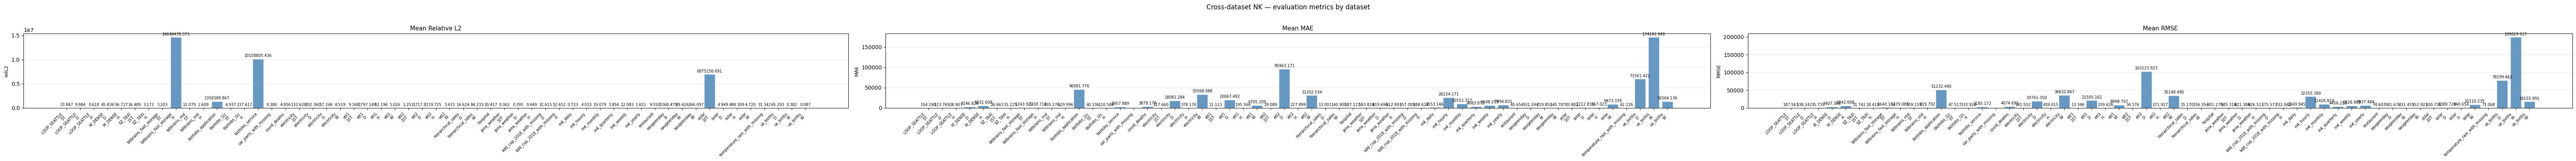

In [7]:
# ── Metrics bar chart ──────────────────────────────────────────────────────
if results:
    ds_labels = [d.replace("/", "\n") for d in results]
    rel_l2s   = [results[d]["mean_relL2"]  for d in results]
    maes      = [results[d]["mean_MAE"]    for d in results]
    rmses     = [results[d]["mean_RMSE"]   for d in results]
    n_ds      = len(ds_labels)

    fig, axes = plt.subplots(1, 3, figsize=(max(12, n_ds * 1.2), 4))
    bar_kw    = dict(color="steelblue", alpha=0.82, edgecolor="white")

    for ax, vals, title, ylabel in zip(
        axes,
        [rel_l2s, maes, rmses],
        ["Mean Relative L2", "Mean MAE", "Mean RMSE"],
        ["relL2", "MAE", "RMSE"],
    ):
        bars = ax.bar(range(n_ds), vals, **bar_kw)
        ax.bar_label(bars, labels=[f"{v:.3f}" for v in vals], fontsize=7, padding=2)
        ax.set_xticks(range(n_ds))
        ax.set_xticklabels(ds_labels, fontsize=7, rotation=45, ha="right")
        ax.set_title(title, fontsize=11)
        ax.set_ylabel(ylabel, fontsize=9)
        ax.grid(axis="y", alpha=0.3)

    fig.suptitle("Cross-dataset NK — evaluation metrics by dataset", fontsize=12, y=1.02)
    plt.tight_layout()
    plt.show()
else:
    print("No results to plot — run cell 6 first.")


/Users/jonghyeonlee/KMD_TS/experiments/../gift_eval/data.py:151: FutureWarning: 'T' is deprecated and will be removed in a future version, please use 'min' instead.
  freq = norm_freq_str(to_offset(self.freq).name)
/Users/jonghyeonlee/KMD_TS/experiments/../gift_eval/data.py:151: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  freq = norm_freq_str(to_offset(self.freq).name)


[fig saved → ../experiments/figures/cross_dataset_fig03.png]


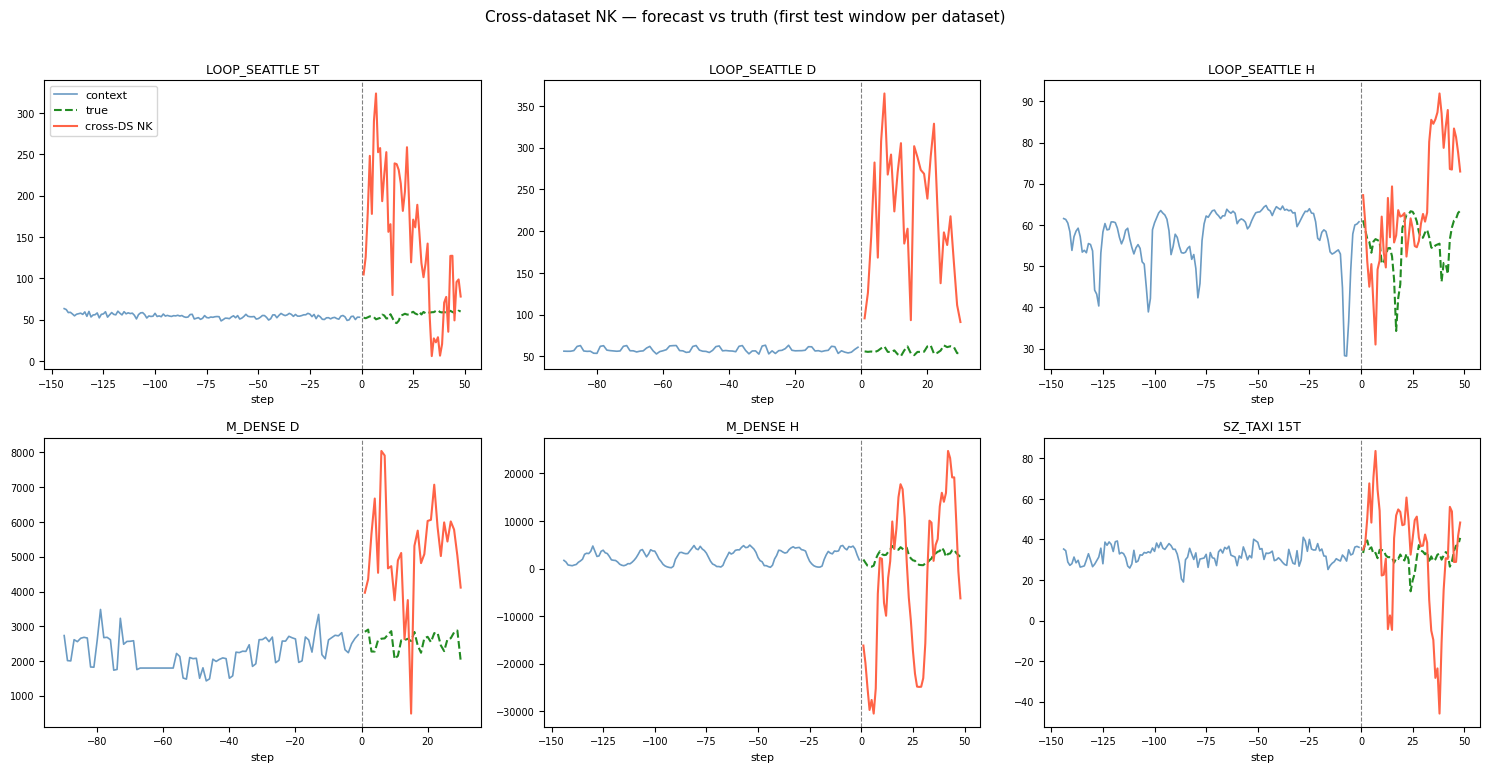

In [8]:
# ── Forecast comparison on real test windows ──────────────────────────────
#
# For up to 6 datasets, show the first evaluable test window:
# context (blue) | true horizon (green dashed) | cross-dataset NK (red).

if HAS_GIFT and eval_states:
    n_show   = min(6, len(eval_states))
    show_st  = eval_states[:n_show]
    ncols    = min(3, n_show)
    nrows    = (n_show + ncols - 1) // ncols

    fig, axes = plt.subplots(nrows, ncols,
                             figsize=(5 * ncols, 3.8 * nrows),
                             squeeze=False)

    for panel_idx, (s, ax) in enumerate(zip(show_st, axes.ravel())):
        ds_name = s["dataset_name"]
        H       = int(s["horizon_length"])
        L       = H * CONTEXT_MULT

        try:
            ds = Dataset(name=ds_name, term="short")
        except Exception:
            ax.set_visible(False)
            continue

        found = False
        for ctx_entry, lbl_entry in ds.test_data:
            ctx_raw = np.asarray(ctx_entry["target"], dtype=float).ravel()
            tgt_raw = np.asarray(lbl_entry["target"], dtype=float).ravel()
            if len(ctx_raw) < L or len(tgt_raw) < H:
                continue

            ctx_raw = ctx_raw[-L:]
            tgt_raw = tgt_raw[:H]

            loc   = float(np.nanmedian(ctx_raw))
            devs  = np.abs(ctx_raw - loc)
            scale = max(float(np.nanquantile(devs, 0.75)) if np.any(np.isfinite(devs)) else 1.0, 1e-8)
            ctx_norm = (ctx_raw - loc) / scale
            pred_norm = cdnk.predict(ctx_norm, target_horizon=H)
            pred = pred_norm * scale + loc

            t_ctx = np.arange(-L, 0)
            t_h   = np.arange(1, H + 1)
            ax.plot(t_ctx, ctx_raw, color="steelblue", lw=1.2, alpha=0.8, label="context")
            ax.axvline(0, color="gray", lw=0.8, ls="--")
            ax.plot(t_h, tgt_raw, color="forestgreen", lw=1.5, ls="--", label="true")
            ax.plot(t_h, pred,    color="tomato",      lw=1.5, label="cross-DS NK")
            ax.set_title(ds_name.replace("/", " "), fontsize=9)
            ax.set_xlabel("step", fontsize=8)
            ax.tick_params(labelsize=7)
            found = True
            break

        if not found:
            ax.text(0.5, 0.5, "no test window", ha="center", va="center",
                    transform=ax.transAxes, fontsize=9)

    # Hide unused panels
    for ax in axes.ravel()[n_show:]:
        ax.set_visible(False)

    axes.ravel()[0].legend(fontsize=8, loc="upper left")
    fig.suptitle("Cross-dataset NK — forecast vs truth (first test window per dataset)",
                 fontsize=11, y=1.01)
    plt.tight_layout()
    plt.show()
else:
    print("No evaluated states — run cells 6 first.")


[fig saved → ../experiments/figures/cross_dataset_fig04.png]


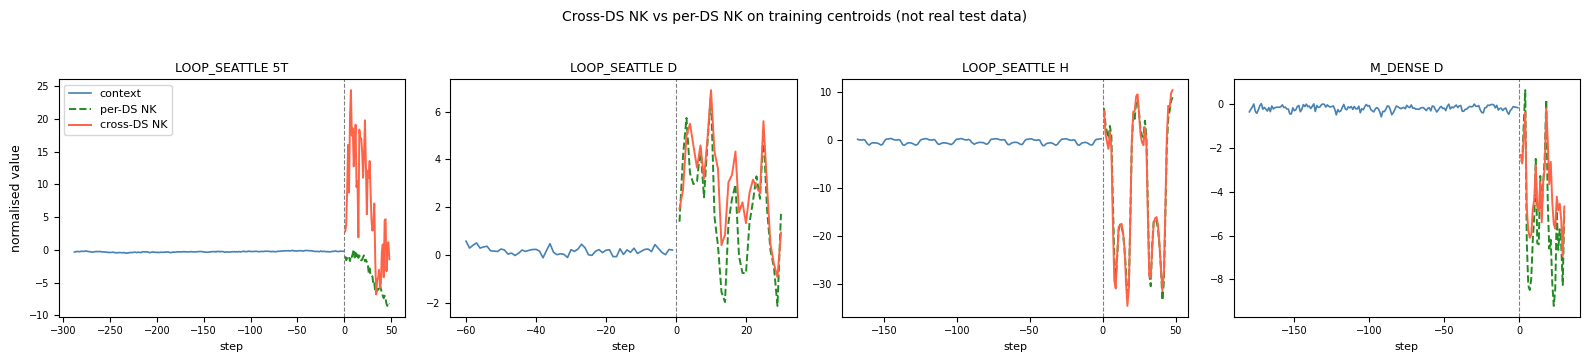

In [9]:
# ── Cross-dataset vs per-dataset NK on training centroids ─────────────────
#
# Uses each dataset's own centroids as synthetic query contexts.
# "per-dataset NK" here is the centroid_pred stored in the .npz state.
# This is NOT real test data — it shows how the cross-dataset model
# approximates the per-dataset model on its own training support.

if states:
    n_show = min(4, len(states))
    fig, axes = plt.subplots(1, n_show, figsize=(4 * n_show, 3.5), sharey=False)
    if n_show == 1:
        axes = [axes]

    for i, (s, ax) in enumerate(zip(states[:n_show], axes)):
        H0    = int(s["horizon_length"])
        L0    = int(s["context_length"])
        ctx   = s["centroids"][0]          # first centroid
        true_h = s["centroid_preds"][0]    # per-dataset NK prediction (stored)
        pred_h = cdnk.predict(ctx, target_horizon=H0)

        t_ctx = np.arange(-L0, 0)
        t_h   = np.arange(1, H0 + 1)

        ax.plot(t_ctx, ctx,    color="steelblue",  lw=1.2, label="context")
        ax.axvline(0, color="gray", lw=0.8, ls="--")
        ax.plot(t_h, true_h,  color="forestgreen", lw=1.4, ls="--", label="per-DS NK")
        ax.plot(t_h, pred_h,  color="tomato",      lw=1.4, label="cross-DS NK")
        ax.set_title(s["dataset_name"].replace("/", " "), fontsize=9)
        ax.set_xlabel("step", fontsize=8)
        ax.tick_params(labelsize=7)

    axes[0].set_ylabel("normalised value", fontsize=9)
    axes[0].legend(fontsize=8, loc="upper left")
    fig.suptitle("Cross-DS NK vs per-DS NK on training centroids (not real test data)",
                 fontsize=10, y=1.02)
    plt.tight_layout()
    plt.show()


[fig saved → ../experiments/figures/cross_dataset_fig05.png]


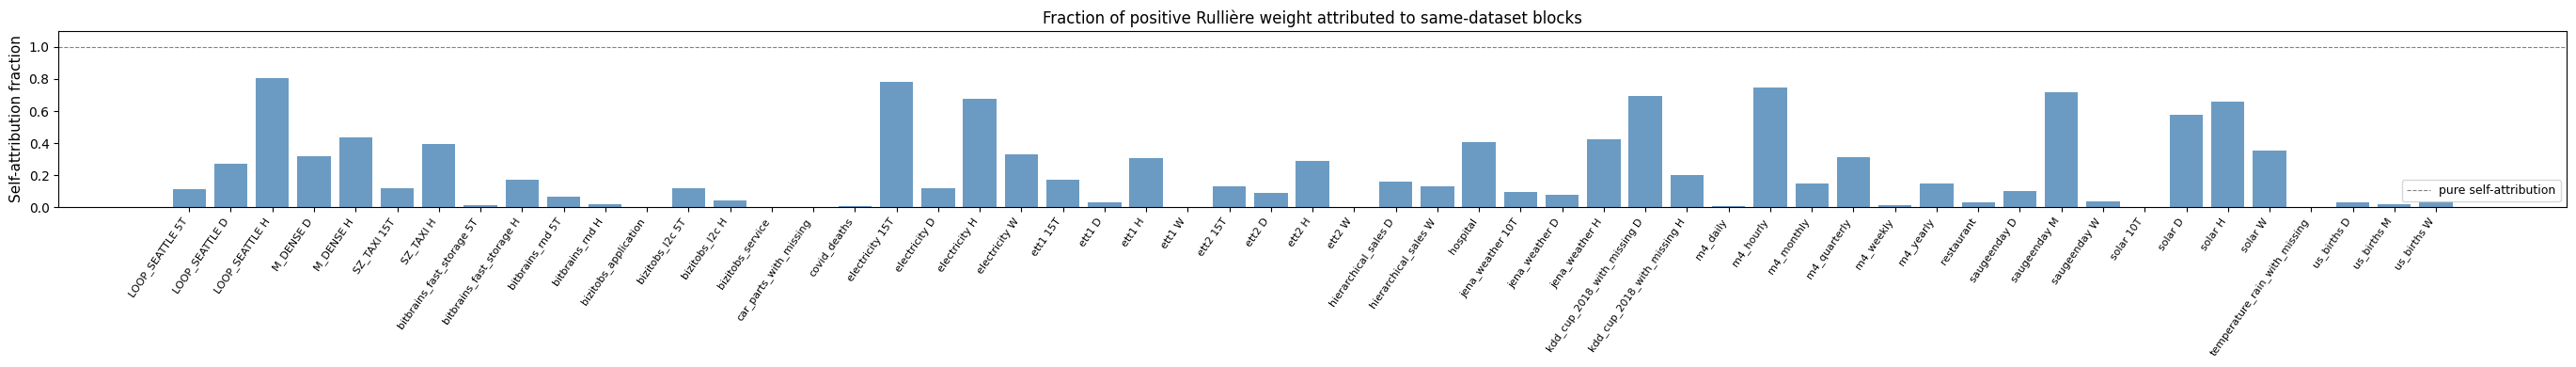

Mean self-attribution : 0.217
Min  self-attribution : 0.000  (bizitobs_application — most cross-dataset borrowing)


In [10]:
# ── Cross-dataset weight self-attribution ─────────────────────────────────
#
# For each dataset, fraction of positive Rullière weight attributed to blocks
# from the SAME dataset vs. all others.
# High self-attribution → cross-dataset model agrees with per-dataset model.
# Low self-attribution  → genuinely borrowing from other datasets.

from src.nested_kriging import _rbf_kernel

self_weights    = []
ds_names_short  = []

# Map each block → its source dataset
block_to_ds = []
for s in states:
    block_to_ds.extend([s["dataset_name"]] * len(s["centroids"]))
block_to_ds_arr = np.array(block_to_ds)

for s in states:
    ds = s["dataset_name"]
    q_ctx = s["centroids"].mean(axis=0)        # mean centroid as representative query
    phi_q = acf_embedding(q_ctx, ACF_DIM)
    c = _rbf_kernel(phi_q[None], cdnk._phi_centroids,
                    length_scale=cdnk.length_scale_,
                    amplitude=cdnk.amplitude).ravel()
    w = np.linalg.solve(cdnk._chol_CD.T, np.linalg.solve(cdnk._chol_CD, c))

    w_pos     = np.maximum(w, 0)
    same_mask = block_to_ds_arr == ds
    self_frac = float(w_pos[same_mask].sum() / (w_pos.sum() + 1e-12))
    self_weights.append(self_frac)
    ds_names_short.append(ds.replace("/", " "))

if self_weights:
    fig, ax = plt.subplots(figsize=(max(10, len(states) * 0.5), 4))
    bars = ax.bar(range(len(self_weights)), self_weights, color="steelblue", alpha=0.8)
    ax.axhline(1.0, color="gray", ls="--", lw=0.8, label="pure self-attribution")
    ax.set_xticks(range(len(states)))
    ax.set_xticklabels(ds_names_short, rotation=55, ha="right", fontsize=8)
    ax.set_ylabel("Self-attribution fraction", fontsize=11)
    ax.set_ylim(0, 1.1)
    ax.set_title("Fraction of positive Rullière weight attributed to same-dataset blocks",
                 fontsize=12)
    ax.legend(fontsize=9)
    plt.tight_layout()
    plt.show()

    print(f"Mean self-attribution : {float(np.mean(self_weights)):.3f}")
    min_idx = int(np.argmin(self_weights))
    print(f"Min  self-attribution : {self_weights[min_idx]:.3f}  "
          f"({ds_names_short[min_idx]} — most cross-dataset borrowing)")


In [11]:
# ── Save cross-dataset evaluation results to JSON ─────────────────────────
import json as _nk_json
import numpy as _nk_np

_nk_results_dir = ROOT / "experiments" / "results"
_nk_results_dir.mkdir(parents=True, exist_ok=True)

_nk_hyperparams = {
    "ACF_DIM":          ACF_DIM,
    "SIGMA_N":          SIGMA_N,
    "CONTEXT_MULT":     CONTEXT_MULT,
    "MAX_EVAL_SERIES":  MAX_EVAL_SERIES,
    "n_states_loaded":  len(states),
    "datasets_loaded":  [s["dataset_name"] for s in states],
}

# Collect per-window error arrays (serialisable)
_nk_per_window = {
    ds: {
        "rel_l2": [float(e) for e in errs["rel_l2"]],
        "mae":    [float(e) for e in errs["mae"]],
        "rmse":   [float(e) for e in errs["rmse"]],
    }
    for ds, errs in all_errors.items()
} if "all_errors" in vars() else {}

_nk_out = {
    "hyperparameters": _nk_hyperparams,
    "summary_metrics": results if "results" in vars() else {},
    "per_window_errors": _nk_per_window,
}

_nk_fpath = _nk_results_dir / "cross_dataset.json"
with open(_nk_fpath, "w") as _nk_f:
    _nk_json.dump(_nk_out, _nk_f, indent=2)
print(f"Cross-dataset results saved → {_nk_fpath}")


Cross-dataset results saved → ../experiments/results/cross_dataset.json
